# Gaussian Process Classification (GPC)
- **Part 1 – Two moons:** how the model behaves far from the data
- **Part 2 – Iris:** how the choice of kernel changes the result

## 0 — Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_moons
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import ConstantKernel as C, RBF

## Part 1 — Two moons
### 1.1 Data

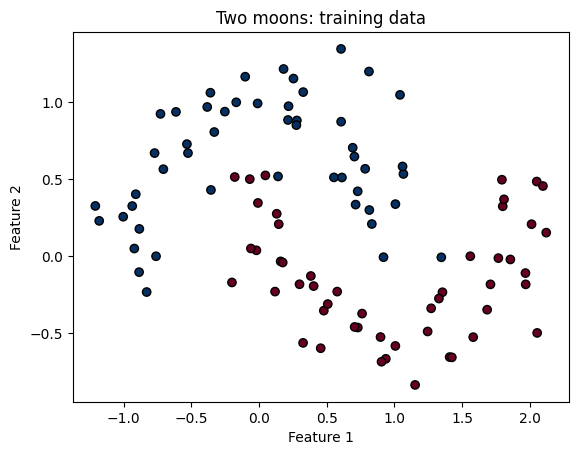

In [4]:
X, y = make_moons(n_samples=100, noise=0.2, random_state=0)
plt.scatter(X[:,0], X[:,1], c=y, cmap="RdBu_r", edgecolor="k")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two moons: training data")
plt.show()

### 1.2 Model

In [5]:
gpc = GaussianProcessClassifier(kernel=C(1.0) * RBF(1.0)).fit(X, y)

# grid wider than the data, to see what happens far away
xx, yy = np.meshgrid(np.linspace(-5, 6, 200), np.linspace(-4.5, 5, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
p_grid = gpc.predict_proba(grid)[:, 1].reshape(xx.shape)

### 1.3 Probability map
White = 0.5 → the model does not know. Far from the data, it goes back to 0.5.

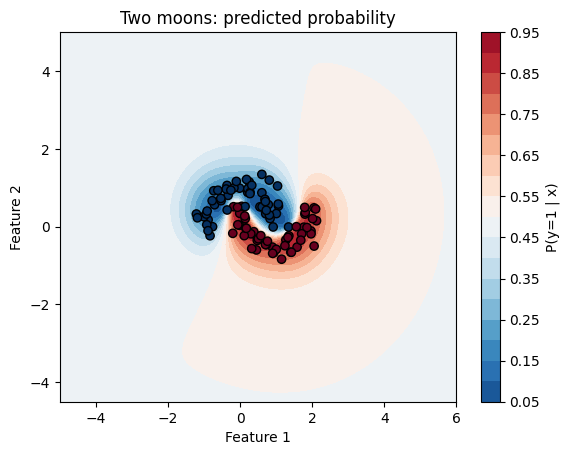

In [7]:
plt.contourf(xx, yy, p_grid, levels=20, cmap="RdBu_r", vmin=0, vmax=1)
plt.colorbar(label="P(y=1 | x)")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", edgecolor="k")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two moons: predicted probability")
plt.show()

## Part 2 — Iris: comparing kernels
Same data, two kernels. Higher LML (log-marginal likelihood) = better fit.
- **RBF:** prediction depends on the distance between points
- **Constant:** no dependence on x (baseline)

Colour = most probable class; intensity = confidence.

In [8]:
iris = load_iris()
X = iris.data[:, :2]  # only the first two features
y = iris.target

kernel = 1.0 * RBF([1.0])
gpc_rbf_RBF = GaussianProcessClassifier(kernel=kernel).fit(X, y)
kernel = 1.0 * C(1.0)
gpc_rbf_C = GaussianProcessClassifier(kernel=kernel).fit(X, y)

### 2.1 Grid and colours

In [9]:
h = 0.02
xx, yy = np.meshgrid(
    np.arange(X[:, 0].min() - 1, X[:, 0].max() + 1, h),
    np.arange(X[:, 1].min() - 1, X[:, 1].max() + 1, h),
)

cmaps = ["Blues", "Greens", "Reds"]
levels = np.arange(0.30, 1.0001, 0.05)
pt_colors = [plt.get_cmap(c)(0.9) for c in cmaps]

### 2.2 Decision maps

c:\Users\joral\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\contour.py:1454: UserWarning: Warning: converting a masked element to nan.
  self.zmax = float(z.max())
c:\Users\joral\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\contour.py:1455: UserWarning: Warning: converting a masked element to nan.
  self.zmin = float(z.min())


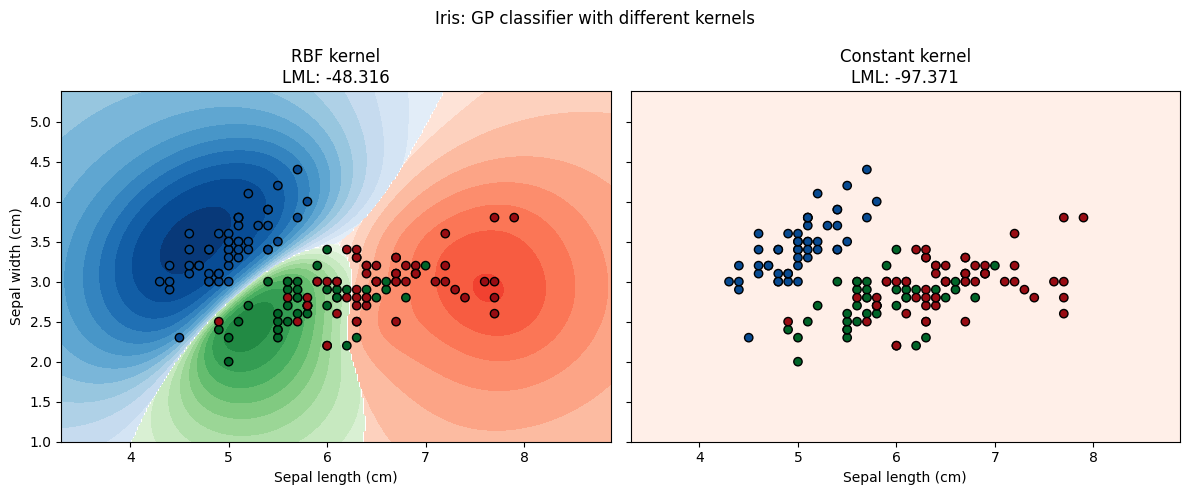

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (title, clf) in zip(axes, [("RBF kernel", gpc_rbf_RBF), ("Constant kernel", gpc_rbf_C)]):
    P = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape + (3,))
    pred = P.argmax(axis=2)

    for k in range(3):
        Zk = np.ma.masked_where(pred != k, P[:, :, k])  # only where class k wins
        ax.contourf(xx, yy, Zk, levels=levels, cmap=cmaps[k], extend="both")

    ax.scatter(X[:, 0], X[:, 1], c=[pt_colors[j] for j in y], edgecolor="k")
    ax.set_xlabel("Sepal length (cm)")
    ax.set_title("%s\nLML: %.3f" % (title, clf.log_marginal_likelihood(clf.kernel_.theta)))

axes[0].set_ylabel("Sepal width (cm)")
fig.suptitle("Iris: GP classifier with different kernels")
plt.tight_layout()
plt.show()